# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dewi Rahma Fauziah
- **Email:** fauziahrahma138@gmail.com
- **ID Dicoding:** DS014B6X0441

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola rata-rata jumlah penyewaan sepeda (cnt) berdasarkan jam (hr) selama periode 2011–2012, dan pada jam berapa permintaan penyewaan mencapai rata-rata tertinggi?
- **Pertanyaan 2:** Bagaimana rata-rata jumlah penyewaan sepeda (cnt) berbeda berdasarkan musim (season) dan kondisi cuaca (weathersit) selama periode 2011–2012, dan kondisi mana yang memiliki rata-rata penyewaan tertinggi?


## Import Semua Packages/Library yang Digunakan

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df Bike Sharing

In [77]:
# Memuat dataset
hour_df = pd.read_csv('hour.csv')
day_df = pd.read_csv('day.csv')

# Melihat ukuran dataset
print("Ukuran dataset per jam:", hour_df.shape)
print("Ukuran dataset per hari:", day_df.shape)

# Menampilkan 5 baris pertama
display(hour_df.head())
display(day_df.head())

Ukuran dataset per jam: (17379, 17)
Ukuran dataset per hari: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset hour.csv berisi 17.379 baris dan 17 kolom yang mencatat data penyewaan sepeda berdasarkan jam.
- Dataset day.csv berisi 731 baris dan 16 kolom yang mencatat data penyewaan sepeda berdasarkan hari. Kedua dataset mencakup periode tahun 2011–2012.

### Assessing Data

#### Identifying data problem

In [78]:
# Memeriksa informasi dataset
print("=== Informasi Dataset ===")
hour_df.info()

# Memeriksa missing values
print("\n=== Missing Values ===")
print(hour_df.isna().sum())

# Memeriksa data duplikat
print("\n=== Data Duplikat ===")
print("Jumlah data duplikat:", hour_df.duplicated().sum())

# Memeriksa statistik deskriptif
print("\n=== Statistik Deskriptif ===")
display(hour_df.describe())

# Memeriksa nilai unik pada kolom kategorikal
print("\n=== Nilai Unik Kolom Kategorikal ===")
categorical_columns = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit'
]

for column in categorical_columns:
    print(f"{column}: {sorted(hour_df[column].unique())}")


# Memeriksa konsistensi jumlah penyewaan
inconsistent_count = hour_df[
    hour_df['cnt'] != hour_df['casual'] + hour_df['registered']
]

print(
    "Jumlah baris dengan total penyewaan tidak konsisten:",
    len(inconsistent_count)
)

# Memeriksa kemungkinan outlier pada jumlah penyewaan
Q1 = hour_df['cnt'].quantile(0.25)
Q3 = hour_df['cnt'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = hour_df[
    (hour_df['cnt'] < lower_bound) |
    (hour_df['cnt'] > upper_bound)
]

print("Batas bawah:", lower_bound)
print("Batas atas:", upper_bound)
print("Jumlah kandidat outlier:", len(outliers))

# Melihat beberapa kandidat outlier
outliers[['dteday', 'hr', 'casual', 'registered', 'cnt']].sort_values(
    by='cnt', ascending=False
).head(10)


=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

=== Missing Values ===

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



=== Nilai Unik Kolom Kategorikal ===
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
hr: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Jumlah baris dengan total penyewaan tidak konsisten: 0
Batas bawah: -321.5
Batas atas: 642.5
Jumlah kandidat outlier: 505


,dteday,hr,casual,registered,cnt
14773,2012-09-12,18,91,886,977
14964,2012-09-20,17,91,885,976
14748,2012-09-11,17,168,802,970
14725,2012-09-10,18,111,857,968
15084,2012-09-25,17,107,860,967
15780,2012-10-24,17,87,876,963
10622,2012-03-23,17,264,693,957
15108,2012-09-26,17,77,876,953
15444,2012-10-10,17,91,857,948
15588,2012-10-16,17,104,839,943


**Steps to Take:**
- Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` agar dapat digunakan untuk analisis berdasarkan tanggal.
- Memeriksa missing values dan data duplikat untuk memastikan kelengkapan serta keunikan data.
- Memeriksa konsistensi jumlah penyewaan dengan membandingkan kolom `cnt` terhadap penjumlahan `casual` dan `registered`.
- Mengidentifikasi kandidat outlier pada kolom `cnt` menggunakan metode Interquartile Range (IQR), kemudian meninjau nilainya sebelum menentukan penanganan yang sesuai.
- Memeriksa nilai unik kolom kategorikal seperti `season` dan `weathersit` agar kode kategorinya lebih mudah dipahami saat analisis.

**Insight:** (Opsional)
- Dataset `hour.csv` memiliki 17.379 baris dan 17 kolom. Hasil pemeriksaan menunjukkan tidak ditemukan missing values maupun baris duplikat.
- Kolom `dteday` masih bertipe `object`, sehingga perlu dikonversi menjadi `datetime64[ns]` agar dapat digunakan untuk analisis berdasarkan tanggal.
- Pemeriksaan konsistensi menunjukkan tidak ada nilai `cnt` yang berbeda dari hasil penjumlahan `casual` dan `registered`.
- Metode Interquartile Range (IQR) mendeteksi 505 kandidat outlier pada kolom `cnt`, dengan batas atas 642,5. Beberapa nilai penyewaan tertinggi tercatat pada pukul 17.00–18.00. Nilai tersebut perlu ditinjau karena dapat mencerminkan tingginya permintaan pada jam sibuk dan tidak otomatis menunjukkan kesalahan data.
- Kolom `season` dan `weathersit` menggunakan angka sebagai kode kategori. Makna setiap kode perlu mengacu pada keterangan dataset agar hasil analisis dapat diinterpretasikan dengan tepat.

### Cleaning Data

#### Fixing data problem

In [79]:
# Mengubah tipe data kolom dteday menjadi datetime
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# Memeriksa tipe data setelah perubahan
print("Tipe data dteday pada hour_df:", hour_df['dteday'].dtype)
print("Tipe data dteday pada day_df:", day_df['dteday'].dtype)

# Menyimpan kedua dataset hasil cleaning
from pathlib import Path

Path("data").mkdir(exist_ok=True)

hour_df.to_csv("data/hour_clean.csv", index=False)
day_df.to_csv("data/day_clean.csv", index=False)

print("hour_clean.csv dan day_clean.csv berhasil disimpan!")


Tipe data dteday pada hour_df: datetime64[ns]
Tipe data dteday pada day_df: datetime64[ns]
hour_clean.csv dan day_clean.csv berhasil disimpan!


**Insight:** (Opsional)
- Kolom `dteday` pada dataset `hour_df` dan `day_df` telah dikonversi menjadi tipe data `datetime64[ns]` agar dapat digunakan untuk analisis berdasarkan tanggal.
- Tidak ada baris yang dihapus karena hasil pemeriksaan tidak menunjukkan adanya missing values maupun data duplikat.
- Kandidat outlier pada kolom `cnt` tetap dipertahankan karena nilai yang tinggi belum tentu merupakan kesalahan data
dan masih dapat mencerminkan tingginya permintaan penyewaan sepeda pada jam tertentu.
- Kolom `season` dan `weathersit` tetap menggunakan kode angka sesuai dataset. Label kategori ditambahkan pada visualisasi agar hasil analisis lebih mudah dipahami.
- Dataset hasil cleaning disimpan sebagai hour_clean.csv dan day_clean.csv untuk digunakan pada tahap analisis dan dashboard.

## Exploratory Data Analysis (EDA)

### Explore Bike Sharing Data

In [80]:
# Pola rata-rata penyewaan sepeda berdasarkan jam
rentals_by_hour = hour_df.groupby('hr')['cnt'].mean()

display(rentals_by_hour)

# Rata-rata penyewaan berdasarkan musim
rentals_by_season = hour_df.groupby('season')['cnt'].mean()

display(rentals_by_season)

# Rata-rata penyewaan berdasarkan kondisi cuaca
rentals_by_weather = hour_df.groupby('weathersit')['cnt'].mean()

display(rentals_by_weather)

# Rata-rata penyewaan berdasarkan kombinasi musim dan cuaca
rentals_by_season_weather = hour_df.groupby(
    ['season', 'weathersit']
)['cnt'].mean().reset_index()

display(rentals_by_season_weather)

,cnt
hr,
0,53.898072
1,33.375691
2,22.869930
3,11.727403
4,6.352941
5,19.889819
6,76.044138
7,212.064649
8,359.011004


,cnt
season,
1,111.114569
2,208.344069
3,236.016237
4,198.868856


,cnt
weathersit,
1,204.869272
2,175.165493
3,111.579281
4,74.333333


,season,weathersit,cnt
0,1,1,122.055535
1,1,2,103.074689
2,1,3,58.650407
3,1,4,74.333333
4,2,1,232.410983
5,2,2,181.261364
6,2,3,115.179803
7,3,1,244.494207
8,3,2,224.848997
9,3,3,171.955390


**Insight:** (Opsional)
- Rata-rata penyewaan sepeda tertinggi berdasarkan jam terjadi pada pukul 17.00, yaitu 461,45 penyewaan, diikuti pukul 18.00 sebesar 425,51 penyewaan. Rata-rata terendah terjadi pada pukul 04.00, yaitu 6,35 penyewaan.
- Berdasarkan musim, rata-rata penyewaan tertinggi terjadi pada musim 3 sebesar 236,02, sedangkan terendah pada musim 1 sebesar 111,11.
- Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terjadi pada kondisi cuaca 1 sebesar 204,87, sedangkan terendah pada kondisi cuaca 4 sebesar 74,33.
- Dari kombinasi musim dan kondisi cuaca yang tercatat, rata-rata penyewaan tertinggi terdapat pada musim 3 dan kondisi cuaca 1, yaitu 244,49 penyewaan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

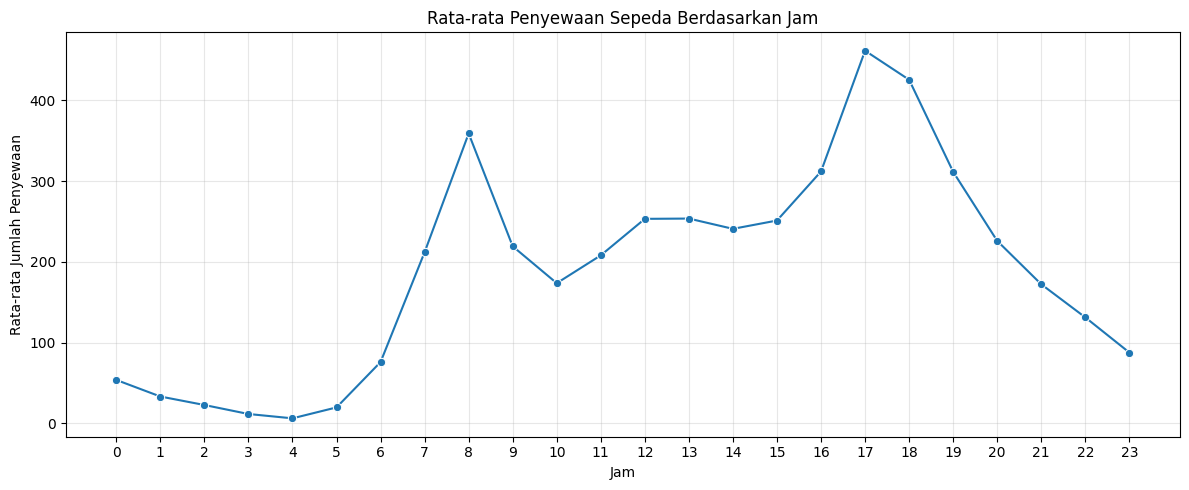

In [81]:
# Rata-rata penyewaan sepeda berdasarkan jam
rentals_by_hour = hour_df.groupby('hr')['cnt'].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(x=rentals_by_hour.index, y=rentals_by_hour.values, marker='o')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

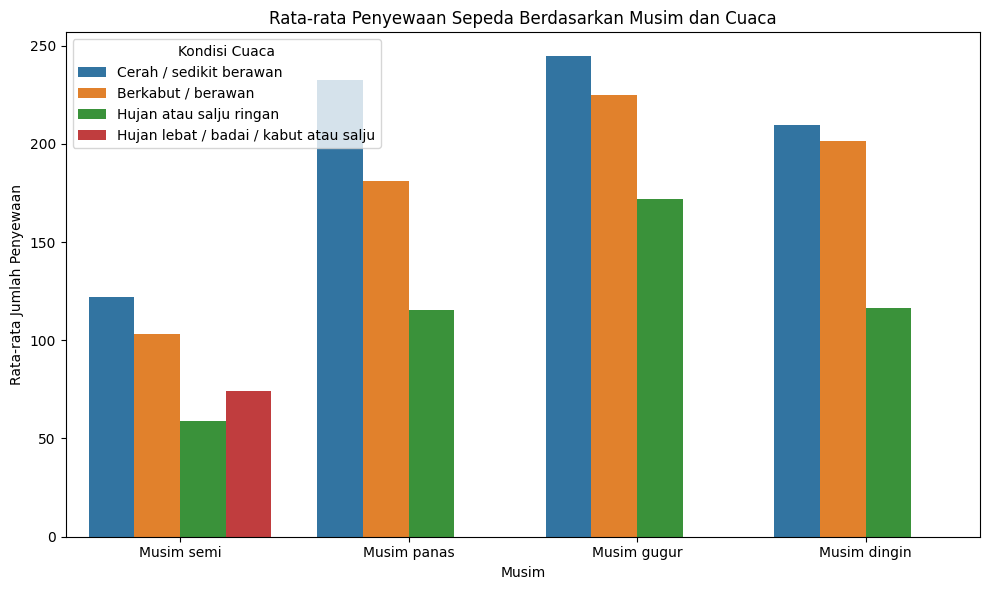

In [82]:
# Memberikan label pada musim dan kondisi cuaca
season_labels = {
    1: 'Musim semi',
    2: 'Musim panas',
    3: 'Musim gugur',
    4: 'Musim dingin'
}

weather_labels = {
    1: 'Cerah / sedikit berawan',
    2: 'Berkabut / berawan',
    3: 'Hujan atau salju ringan',
    4: 'Hujan lebat / badai / kabut atau salju'
}

# Membuat data rata-rata penyewaan berdasarkan musim dan cuaca
rentals_by_season_weather = hour_df.groupby(
    ['season', 'weathersit']
)['cnt'].mean().reset_index()

rentals_by_season_weather['season_label'] = (
    rentals_by_season_weather['season'].map(season_labels)
)
rentals_by_season_weather['weather_label'] = (
    rentals_by_season_weather['weathersit'].map(weather_labels)
)

# Membuat visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(
    data=rentals_by_season_weather,
    x='season_label',
    y='cnt',
    hue='weather_label'
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Musim dan Cuaca')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.legend(title='Kondisi Cuaca')
plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Berdasarkan grafik pertama, rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00, yaitu 461,45 penyewaan, diikuti pukul 18.00 sebesar 425,51 penyewaan. Sementara itu, rata-rata terendah terjadi pada pukul 04.00 sebesar 6,35 penyewaan. Hal ini menunjukkan bahwa penyewaan sepeda cenderung meningkat pada sore hari dan menurun pada dini hari.
- Berdasarkan grafik kedua, rata-rata penyewaan tertinggi dari kombinasi musim dan kondisi cuaca yang tercatat terjadi pada musim gugur dengan cuaca cerah atau sedikit berawan, yaitu 244,49 penyewaan. Secara keseluruhan, musim gugur memiliki rata-rata penyewaan tertinggi sebesar 236,02, sedangkan kondisi cuaca cerah atau sedikit berawan memiliki rata-rata tertinggi sebesar 204,87. Hasil ini menunjukkan adanya perbedaan rata-rata penyewaan berdasarkan musim dan kondisi cuaca.

## Analisis Lanjutan (Opsional)

In [83]:
# Menghitung rata-rata penyewaan berdasarkan jam
rentals_by_hour = hour_df.groupby('hr')['cnt'].mean().reset_index()

# Mengelompokkan tingkat permintaan penyewaan
def categorize_demand(value):
    if value < 100:
        return 'Rendah'
    elif value < 250:
        return 'Sedang'
    else:
        return 'Tinggi'

rentals_by_hour['demand_category'] = rentals_by_hour['cnt'].apply(
    categorize_demand
)

# Menampilkan hasil pengelompokan
display(rentals_by_hour)

,hr,cnt,demand_category
0,0,53.898072,Rendah
1,1,33.375691,Rendah
2,2,22.869930,Rendah
3,3,11.727403,Rendah
4,4,6.352941,Rendah
5,5,19.889819,Rendah
6,6,76.044138,Rendah
7,7,212.064649,Sedang
8,8,359.011004,Tinggi
9,9,219.309491,Sedang


**Insight:** (Opsional)
- Hasil pengelompokan menunjukkan bahwa permintaan penyewaan kategori tinggi terjadi pada pukul 08.00, 12.00–13.00, dan 15.00–19.00. Rata-rata penyewaan tertinggi terjadi pada pukul 17.00 sebesar 461,45 penyewaan.
- Permintaan kategori rendah terjadi pada pukul 00.00–06.00 dan pukul 23.00. Hasil pengelompokan ini dapat membantu pengelola dalam menentukan waktu prioritas ketersediaan sepeda berdasarkan tingkat permintaan.
- Pengelompokan menggunakan batas rata-rata di bawah 100 sebagai kategori rendah, 100 hingga kurang dari 250 sebagai kategori sedang, dan 250 atau lebih sebagai kategori tinggi. Batas tersebut merupakan kriteria yang ditentukan untuk analisis ini.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1: Pola Penyewaan Sepeda Berdasarkan Jam**

  Berdasarkan analisis data periode 2011–2012, rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00, yaitu 461,45 penyewaan, diikuti pukul 18.00 sebesar 425,51 penyewaan. Sementara itu, rata-rata penyewaan terendah terjadi pada pukul 04.00, yaitu 6,35 penyewaan. Hasil ini menunjukkan bahwa permintaan penyewaan cenderung lebih tinggi pada sore hari dan lebih rendah pada dini hari.

- **Conclusion pertanyaan 2: Pola Penyewaan Sepeda Berdasarkan Musim dan Kondisi Cuaca**

  Berdasarkan musim, rata-rata penyewaan tertinggi terjadi pada musim gugur (*fall*, kode 3), yaitu 236,02 penyewaan, sedangkan rata-rata terendah terjadi pada musim semi (*spring*, kode 1), yaitu 111,11 penyewaan. Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi tercatat pada cuaca cerah atau sedikit berawan (kode 1), yaitu 204,87 penyewaan. Dari kombinasi musim dan kondisi cuaca yang tercatat, rata-rata tertinggi ditemukan pada musim gugur dengan cuaca cerah atau sedikit berawan, yaitu 244,49 penyewaan.


**Rekomendasi Action Item:**
- Mengantisipasi jam sibuk: Memastikan ketersediaan sepeda dan melakukan pemantauan kebutuhan pengembalian sepeda, terutama pada pukul 17.00–18.00, agar dapat mengantisipasi tingginya permintaan.
- Menyesuaikan perencanaan berdasarkan musim dan cuaca: Menggunakan pola rata-rata penyewaan berdasarkan musim dan kondisi cuaca sebagai salah satu pertimbangan dalam mengatur distribusi sepeda dan kebutuhan operasional. Perencanaan perlu dievaluasi secara berkala berdasarkan data penyewaan terbaru.